In [55]:
import jax
jax.config.update("jax_enable_x64", True)

import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt

from scipy.special import comb

import sys
sys.path.insert(0, '..')

from mctdhf import *
from utils import *
import pint

# Define units

In [56]:
ureg = pint.UnitRegistry()

typical_freq = 10 * ureg.GHz

omega = 2*np.pi*typical_freq
energy_to_frequency = 1 / ureg.planck_constant
energy_unit = ureg.hbar * omega
length_unit = np.sqrt(ureg.hbar / (ureg.m_e * omega))

KAPPA = (
    (length_unit * ureg.m_e * ureg.e**2 / (4 * ureg.pi * ureg.epsilon_0 * ureg.hbar**2))
    .to(ureg.dimensionless)
    .magnitude
)


def anharm_pot(a, b, center):
    return (
        lambda x: 0.5 * a**2 * (x - center) ** 2 + ((b * a**2) / 3) * (x - center) ** 4
    )


def coulomb(x_1, x_2):
    return KAPPA / np.sqrt((x_1 - x_2) ** 2)

# Set up Sine-DVR basis

In [69]:
num_wells = 4
num_dvr = 64

well_centers = (np.array([-1.5, -0.5, 0.5, 1.5])*ureg.mum / length_unit).to(ureg.dimensionless)
well_widths = (np.array([1, 1, 1, 1])*ureg.mum / length_unit).to(ureg.dimensionless)

alphas = (np.array([7, 9, 11, 13])*ureg.GHz / energy_to_frequency / energy_unit).to(ureg.dimensionless)
betas = (np.array([0.2, 0.2, 0.2, 0.2])*ureg.GHz / energy_to_frequency / energy_unit).to(ureg.dimensionless)

np.testing.assert_equal(len(well_centers), num_wells)
np.testing.assert_equal(len(well_widths), num_wells)
np.testing.assert_equal(len(alphas), num_wells)
np.testing.assert_equal(len(betas), num_wells)

potentials = [anharm_pot(a, b, center) for a, b, center in zip(alphas, betas, well_centers)]

dvr_bases = []
for center, width in zip(well_centers, well_widths):
    dvr = SineDVR(
        x_min=center - 0.5*width,
        x_max=center + 0.5*width,
        num_points=num_dvr,
    )
    dvr_bases.append(dvr)

## Set up single-particle problem and plot the lowest eigenstates

In [70]:
print(dvr_bases[0].get_grid()[-1])
print(dvr_bases[1].get_grid()[0])
print(dvr_bases[1].get_grid()[-1])
print(dvr_bases[2].get_grid()[0])
print(dvr_bases[2].get_grid()[-1])
print(dvr_bases[3].get_grid()[0])

-23.655216687670528 dimensionless
-22.9383919395593 dimensionless
-0.35841237405561444 dimensionless
0.35841237405561405 dimensionless
22.9383919395593 dimensionless
23.655216687670528 dimensionless


/tmp/ipykernel_106923/3758029634.py:14: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  eigvals, eigvecs = np.linalg.eigh(np.asarray(h))
/tmp/ipykernel_106923/3758029634.py:20: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  V = np.asarray(pot(grid))


Well 1 lowest 4 eigenvalues: [ 3.5484 10.7382 18.1075 25.645 ]
Well 1 transition frequencies (GHz): [ 7.1897 14.559  22.0966]
Well 2 lowest 4 eigenvalues: [ 4.5488 13.7406 23.116  32.6655]
Well 2 transition frequencies (GHz): [ 9.1918 18.5672 28.1167]
Well 3 lowest 4 eigenvalues: [ 5.549  16.7422 28.1217 39.6792]
Well 3 transition frequencies (GHz): [11.1932 22.5727 34.1302]
Well 4 lowest 4 eigenvalues: [ 6.5491 19.7433 33.1257 46.6891]
Well 4 transition frequencies (GHz): [13.1942 26.5766 40.14  ]


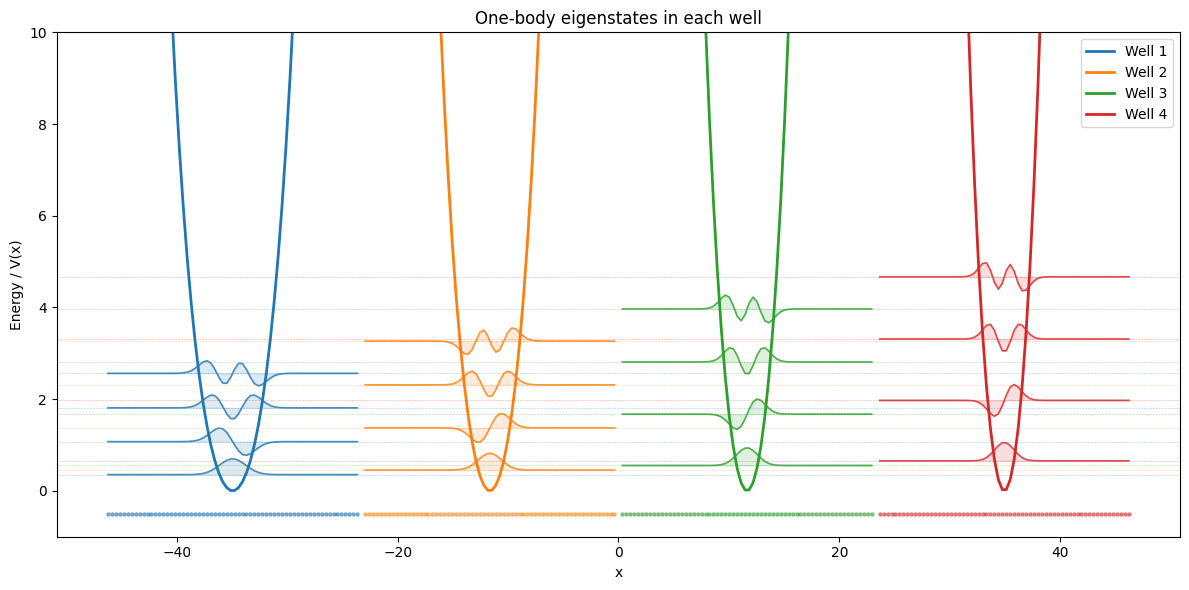

In [71]:
num_eigenstates = 4
wf_scale = 0.5  # visual amplitude scaling

fig, ax = plt.subplots(figsize=(12, 6))

h_list = []

for i, (dvr, pot) in enumerate(zip(dvr_bases, potentials)):
    grid = dvr.get_grid()
    h = dvr.get_h(potential=pot)
    h_list.append(jnp.array(h, dtype=jnp.float32))

    # Diagonalize in the DVR basis (h is symmetric)
    eigvals, eigvecs = np.linalg.eigh(np.asarray(h))

    # DVR eigenvectors normalized with sqrt(dx) so ψ(x_i) = c_i / sqrt(dx)
    psi_dvr = eigvecs / np.sqrt(dvr.dx)

    # Plot the potential
    V = np.asarray(pot(grid))
    ax.plot(grid, V, f"C{i}", lw=2, label=f"Well {i+1}")
    ax.scatter(grid, np.zeros_like(grid) - 0.5, color = f"C{i}", s=5, alpha=0.5)

    # Overlay wavefunctions offset by their eigenvalues
    for n in range(num_eigenstates):
        E_n = eigvals[n]
        wf = psi_dvr[:, n]
        # Fix sign so peak is positive
        if wf[np.argmax(np.abs(wf))] < 0:
            wf = -wf
        ax.axhline(E_n, color=f"C{i}", ls="--", lw=0.4, alpha=0.4)
        ax.plot(grid, E_n + wf_scale * wf, f"C{i}", lw=1.2, alpha=0.8)
        ax.fill_between(grid, E_n, E_n + wf_scale * wf, color=f"C{i}", alpha=0.15)

    print(f"Well {i+1} lowest {num_eigenstates} eigenvalues:",
          np.array2string(eigvals[:num_eigenstates]*(energy_unit*energy_to_frequency).to(ureg.GHz).magnitude, precision=4))
    print(f"Well {i+1} transition frequencies (GHz):",
          np.array2string((eigvals[1:num_eigenstates] - eigvals[0])*(energy_unit*energy_to_frequency).to(ureg.GHz).magnitude, precision=4))

ax.set_xlabel("x")
ax.set_ylabel("Energy / V(x)")
ax.set_title("One-body eigenstates in each well")
ax.legend(loc="upper right")
ax.set_ylim(-1, 10)
plt.tight_layout()
plt.show()

## Compute inter-species Coulomb interaction elements

Since the particles are in separate wells, we only have inter-species interactions.
For DVR, the interaction matrix is 2D: `g[i,j] = V(x_i, x_j) * dx1 * dx2`

In [72]:
# Compute g_dict for all species pairs
# For DVR, g is 2D: g[i,j] = V(x_i, x_j) * dx_i * dx_j
g_dict = {}

for s1 in range(num_wells):
    for s2 in range(s1, num_wells):  # Only upper triangle, transpose handles rest
        if s1 != s2:
            # Same species (intra-well interaction)
            #g = dvr_bases[s1].get_g(coulomb)
        #else:
            # Different species (inter-well interaction)
            g = dvr_bases[s1].get_g_cross_species(dvr_bases[s2], coulomb)
            g_dict[(s1, s2)] = jnp.array(g, jnp.float32)

# Set up MCTDH calculation

In [73]:
print("Number of single excitation states:", comb(num_wells, 1, exact=True, repetition=True))
print("Number of double excitation states:", comb(num_wells, 2, exact=True, repetition=True))
print("Number of triple excitation states:", comb(num_wells, 3, exact=True, repetition=True))
print("Number of quadruple excitation states:", comb(num_wells, 4, exact=True, repetition=True))
print("Total number of states up to quadruple excitations:", comb(num_wells+1, 4, exact=True, repetition=True))

Number of single excitation states: 4
Number of double excitation states: 10
Number of triple excitation states: 20
Number of quadruple excitation states: 35
Total number of states up to quadruple excitations: 70


In [74]:
# MCTDHF parameters
num_particles = [1]*num_wells  # One particle per species
num_mctdhf_orbitals = [4]*num_wells  # MCTDHF orbitals per species
num_spatial_orbitals = [num_dvr]*num_wells  # DVR grid points
num_states = 50

# Create MCTDHF object (use DVR variant for 2D interaction matrices)
mctdhf = MCTDHF_n_species_DVR(
    h_list=h_list,
    g_dict=g_dict,
    num_particles=num_particles,
    num_mctdhf_orbitals=num_mctdhf_orbitals,
    num_spatial_orbitals=num_spatial_orbitals,
    num_states=num_states,
    imag_time=True,
    state_weights=np.concatenate([np.ones(1), 0.5*np.ones(4), np.zeros(num_states-5)])
)

## Run imaginary time calculation

In [75]:
# Integration parameters
dt = 1e-1
num_steps = 500

# Create integrator
integrator = get_cmf_integrator(mctdhf, dt, c_propagator="diagonalize", b_propagator="sil")
#integrator = get_cmf_half_step_integrator(mctdhf, dt, c_propagator="diagonalize", b_propagator="sil")

ts, ys = mctdhf.integrate(
    integrator=integrator,
    num_steps=num_steps,
    t_init=0.0,
    normalize=True,
    noise_bs=0,
    noise_C=1e-3,
    save_every=10
)

Species 0: lowest eigenvalues = [0.35484475 1.073819   1.8107493  2.5645046 ]
Species 1: lowest eigenvalues = [0.45487747 1.3740617  2.3115995  3.2665474 ]
Species 2: lowest eigenvalues = [0.55489856 1.6742212  2.8121655  3.9679215 ]
Species 3: lowest eigenvalues = [0.65491396 1.9743348  3.3125699  4.6689105 ]


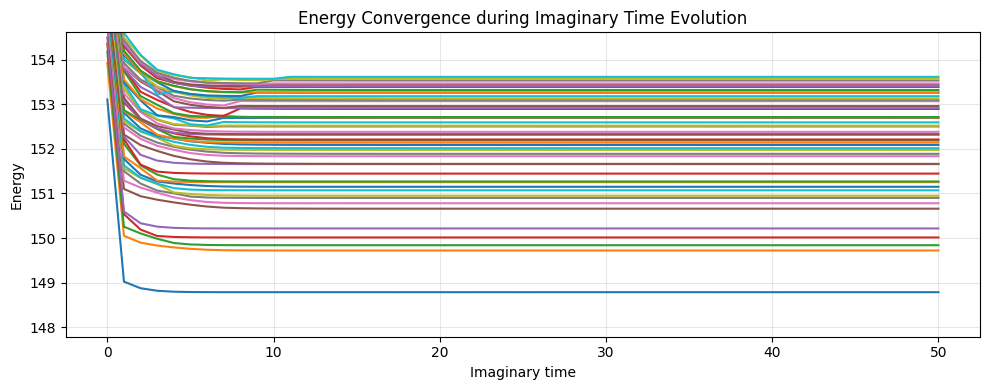

Final energy: [148.78369 149.71939 149.8381  150.01247 150.2142  150.65799 150.78046
 150.90027 150.94933 151.07065 151.15    151.2539  151.26892 151.44568
 151.65923 151.66432 151.83592 151.88959 151.97647 152.01663 152.08882
 152.14095 152.19226 152.21143 152.31761 152.33154 152.38278 152.50406
 152.52277 152.59573 152.69504 152.7046  152.71593 152.89725 152.91483
 152.96153 153.07141 153.09544 153.13385 153.1835  153.26329 153.26851
 153.32326 153.39156 153.40915 153.4499  153.46948 153.53522 153.57446
 153.61752]
Final transition energies: [0.93569946 1.0544128  1.228775   1.4305115  1.8742981  1.9967651
 2.1165771  2.1656342  2.2869568  2.3663025  2.4702148  2.4852295
 2.6619873  2.875534   2.8806305  3.0522308  3.105896   3.1927795
 3.2329407  3.30513    3.357254   3.4085693  3.4277344  3.5339203
 3.5478516  3.5990906  3.7203674  3.7390747  3.8120422  3.9113464
 3.9209137  3.9322357  4.113556   4.131134   4.177841   4.2877197
 4.3117523  4.3501587  4.399811   4.479599   4.4848175

In [76]:
# Calculate energies at each time step
energies = [mctdhf.calculate_energy(t, y) for t, y in zip(ts, ys)]
energies = np.array(energies)

# Plot energy convergence
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ts, np.real(energies))
ax.set_xlabel('Imaginary time')
ax.set_ylabel('Energy')
ax.set_title('Energy Convergence during Imaginary Time Evolution')
ax.grid(True, alpha=0.3)

plt.ylim(energies[-1,0]-1, energies[-1,-1]+1)

plt.tight_layout()
plt.show()

print(f"Final energy: {np.real(energies[-1])}")
print(f"Final transition energies: {np.real(energies[-1, 1:] - energies[-1,0])}")

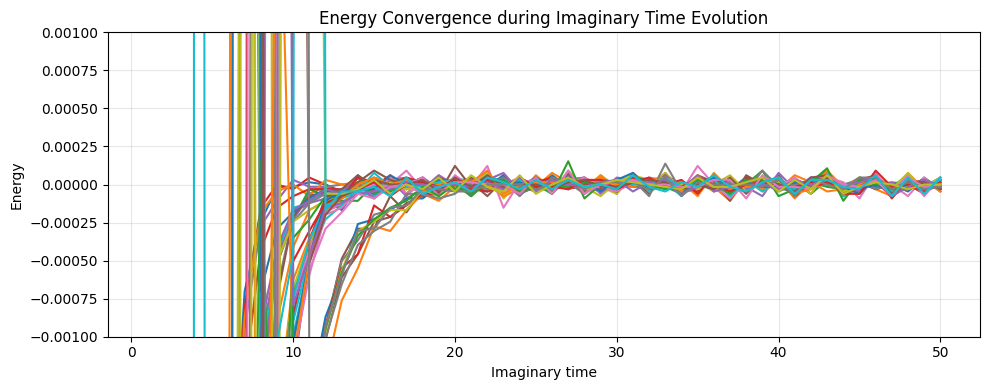

In [77]:
# Plot energy convergence
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ts[1:], np.diff(np.real(energies), axis=0))
ax.set_xlabel('Imaginary time')
ax.set_ylabel('Energy')
ax.set_title('Energy Convergence during Imaginary Time Evolution')
ax.grid(True, alpha=0.3)

plt.ylim(-1e-3, 1e-3)

plt.tight_layout()
plt.show()

In [78]:
# Extract final state.
# Rotate into the natural-orbital gauge first so the state-averaged 1-RDMs are
# diagonal per species and the CI tensor is as sparse as possible. This is an
# exact gauge transform — energies and densities are unchanged — and it gives
# the subsequent Jacobi localization a cleaner starting point.
y_no = mctdhf.rotate_to_natural_orbitals(ys[-1])
y_final, y_char, loc_groups = mctdhf.localize_states(y_no, verbose=True, energy_tol=1.5e-3)
C_final, bs_final = mctdhf._y_to_Cb(y_final)

# Build state -> group index mapping for plotting
state_to_group = {}
for g_idx, group in enumerate(loc_groups):
    for s in group:
        state_to_group[s] = g_idx

# Get SPFs for density calculation
spf_list = [jnp.array(dvr.get_spf()) for dvr in dvr_bases]

# Calculate particle densities
densities = mctdhf.calculate_particle_densities(C_final, bs_final, spf_list)

  State energies: ['148.783691', '149.719391', '149.838074', '150.012451', '150.214188', '150.657974', '150.780426', '150.900238', '150.949341', '151.070663', '151.149994', '151.253906', '151.268875', '151.445648', '151.659180', '151.664322', '151.835922', '151.889572', '151.976456', '152.016617', '152.088852', '152.140930', '152.192261', '152.211411', '152.317581', '152.331512', '152.382797', '152.504059', '152.522766', '152.595703', '152.695023', '152.704590', '152.715881', '152.897278', '152.914795', '152.961533', '153.071396', '153.095428', '153.133850', '153.183487', '153.263290', '153.268494', '153.323257', '153.391541', '153.409119', '153.449905', '153.469513', '153.535217', '153.574432', '153.617523']
  Group 0: states [0], E ≈ 148.783691, size=1
  Group 1: states [1], E ≈ 149.719391, size=1
  Group 2: states [2], E ≈ 149.838074, size=1
  Group 3: states [3], E ≈ 150.012451, size=1
  Group 4: states [4], E ≈ 150.214188, size=1
  Group 5: states [5], E ≈ 150.657974, size=1
  Gro

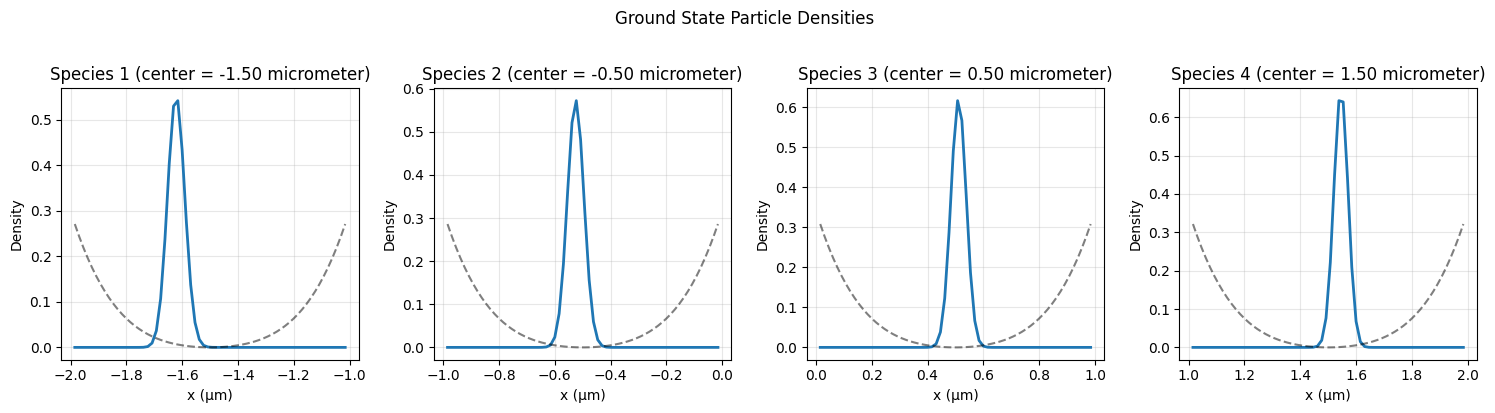

In [79]:
# Plot final densities
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for i, (dvr, density, center) in enumerate(zip(dvr_bases, densities, well_centers)):
    ax = axes[i]
    grid = dvr.get_grid()
    grid_mum = grid * length_unit.to(ureg.mum).magnitude
    rho = np.real(np.array(density[0]))  # First state
    
    # Plot density
    ax.plot(grid_mum, rho.T, linewidth=2)
    ax.fill_between(grid_mum, 0, rho[0], alpha=0.3)
    ax.fill_between(grid_mum, 0, rho[1], alpha=0.3)
    
    # Plot potential (scaled for visibility)
    pot = potentials[i](grid)
    ax.plot(grid_mum, pot / pot.max() * rho.max() * 0.5, 'k--', alpha=0.5, label='V(x) (scaled)')
    
    ax.set_xlabel('x (µm)')
    ax.set_ylabel('Density')
    ax.set_title(f'Species {i+1} (center = {center*length_unit.to(ureg.mum):.2f})')
    ax.grid(True, alpha=0.3)

plt.suptitle('Ground State Particle Densities', y=1.02)
plt.tight_layout()
plt.show()



In [80]:
# Plot all densities with coefficient table to the right
fig, axs = plt.subplots(num_states, 1, figsize=(16, 4*num_states), sharex=True)
fig.subplots_adjust(right=0.6)

for n in range(num_states):
    coeff_text = format_coefficient_table(C_final, n, 1e-1)

    for i, (dvr, density) in enumerate(zip(dvr_bases, densities)):
        grid = dvr.get_grid()
        rho = np.real(np.array(density[n]))
        axs[n].plot(grid, rho, color=f"C{i}", linewidth=2, label=f'Species {i+1}')
        axs[n].fill_between(grid, 0, rho, color=f"C{i}", alpha=0.2)

    axs[n].set_ylabel('Density')
    axs[n].set_title(f"State {n} (group {state_to_group[n]}), Energy = {np.real(energies[-1,n]):.3f}")
    axs[n].grid(True, alpha=0.3)
    #axs[n].legend(loc='upper left', bbox_to_anchor=(1, 0.9))
    axs[n].text(1.02, 0.98, coeff_text, transform=axs[n].transAxes, fontsize=8, fontfamily='monospace',
                verticalalignment='top', horizontalalignment='left',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='wheat', alpha=0.5))


axs[-1].set_xlabel('x')
plt.tight_layout(rect=[0, 0, 0.6, 1])
plt.show()


# Qubit-like parameter optimization

Pick (α, β) per well so that the lowest 16 many-body eigenstates of the coupled MCTDHF Hamiltonian are clean Hartree products of a 4-qubit basis |n₁n₂n₃n₄⟩, n_s ∈ {0, 1}.

The pipeline below mirrors `test/optimize_qubit_params.py` but is inlined for inspection. Steps:

1. **Evaluator** — given (α, β) in GHz, run state-averaged ITE with 50 states, Rayleigh–Ritz post-diagonalise to get true eigenstates of H on the converged subspace, build a qubit target basis from the natural orbitals of the state-averaged 1-RDM over the lowest 16 eigenstates, and compute the fidelity matrix + Hungarian-matched loss.
2. **Sanity check** — call the evaluator at the physical starting point and inspect the matched ladder.
3. **Nelder–Mead** — scipy on the 8-vector [α₀..α₃, β₀..β₃] (GHz), warm-starting each ITE from the previous converged state.
4. **Inspect best** — re-evaluate at (α*, β*) and plot.

## Step 1 — One-shot evaluator: ITE → Rayleigh–Ritz → fidelity

`evaluate_params(α, β)` is the inner loop the optimiser will call. Pipeline:

1. Build per-well DVR Hamiltonians from `anharm_pot` at the requested (α, β).
2. Construct an `MCTDHF_n_species_DVR` solver with `imag_time=True` and `num_states=50` (need ≥36 to reach |1111⟩, plus headroom for non-qubit "intruder" eigenstates in the same energy band — these are doubly-/triply-/quadruply-excited-in-one-well configurations that legitimately live below |1111⟩).
3. Propagate via the half-step CMF integrator with SIL sub-propagators. State-averaged ITE drives the 50 states to span the lowest-50-energy subspace of H projected onto the orbital span.
4. **Rayleigh–Ritz**: state-averaged ITE only converges the *subspace*, not the individual eigenbasis within it. Build `H_{IJ} = ⟨Ψ_I|H|Ψ_J⟩` on the converged subspace, solve the generalised eigenproblem against `S_{IJ} = ⟨Ψ_I|Ψ_J⟩`, and rotate the CI tensor accordingly. Orbitals are unchanged.
5. **Qubit target basis**: average the 1-RDMs over the 16 lowest eigenstates per species, eigh, take the two leading natural orbitals as `|0⟩_s, |1⟩_s`. (Bare-well eigenstates are the wrong target: with KAPPA ≈ 811 the MCTDHF orbitals are heavily Coulomb-dressed, and `|⟨v_bare|b_MCTDHF⟩|² ≈ 0.4–0.5` per species would break the Hartree-product factorisation.)
6. Compute `F[k, n] = |⟨n₁n₂n₃n₄|Ψ_k⟩|²` and use Hungarian matching to assign each of the 16 configs to a distinct eigenstate. Loss = 16 − Σ_n F.

In [53]:
from utils import *
from optimize_qubit_params import *
from optimize_qubit_params import _ghz_to_dimensionless, _build_h_list, _rayleigh_ritz

# ── Step 1 code: define the evaluator (ITE → RR → fidelity) ───────────────────

# Reuse the geometry built in earlier cells: dvr_bases, g_dict, well_centers,
# typical_freq, anharm_pot, num_wells, num_dvr.


print(iter_bitstrings(4, 2))

[(0, 0, 0, 0), (0, 0, 0, 1), (0, 0, 1, 0), (0, 0, 1, 1), (0, 1, 0, 0), (0, 1, 0, 1), (0, 1, 1, 0), (0, 1, 1, 1), (1, 0, 0, 0), (1, 0, 0, 1), (1, 0, 1, 0), (1, 0, 1, 1), (1, 1, 0, 0), (1, 1, 0, 1), (1, 1, 1, 0), (1, 1, 1, 1)]


## Step 2 — Sanity check at the physical starting point

α=[7, 8, 9, 10] GHz gives single-excitation detunings ~1 GHz between adjacent wells (well above inter-well Coulomb J at 1 μm separation). β=0.15 GHz makes each well's |2⟩-anharmonicity comparable to J, so doubly-excited states stay split off from the qubit subspace. Expectation: |0000⟩ → state 0 with F ≈ 1, single excitations match low-lying states, higher excitations progressively more hybridised.

In [54]:
num_states = 50
num_steps = 500

alphas = _ghz_to_dimensionless([7., 8., 9., 10.])    # GHz — single-excitation detunings ~1 GHz
betas  = _ghz_to_dimensionless([0.2] * num_wells)   # GHz — anharmonicity comparable to inter-well J at ~1 µm

h_list = _build_h_list(alphas, betas)

mctdhf = MCTDHF_n_species_DVR(
    h_list=h_list,
    g_dict=G_DICT,
    num_particles=[1] * NUM_WELLS,
    num_mctdhf_orbitals=[NUM_MCTDHF_ORBITALS] * NUM_WELLS,
    num_spatial_orbitals=[NUM_DVR] * NUM_WELLS,
    num_states=num_states,
    imag_time=True,
    state_weights=np.concatenate([np.ones(1), 0.5*np.ones(4), np.zeros(num_states-5)])
)

integrator = get_cmf_integrator(
    mctdhf, dt=1e-1, c_propagator="diagonalize", b_propagator="sil"
    )


ts, ys = mctdhf.integrate(
    integrator=integrator,
    num_steps=num_steps,
    t_init=0.0,
    normalize=True,
    noise_bs=0,
    noise_C=1e-3,
    save_every=1,
)

Species 0: lowest eigenvalues = [0.35484475 1.073819   1.8107493  2.5645046 ]
Species 1: lowest eigenvalues = [0.4048632 1.2239544 2.061222  2.9156368]
Species 2: lowest eigenvalues = [0.45487747 1.3740617  2.3115995  3.2665474 ]
Species 3: lowest eigenvalues = [0.50488937 1.5241492  2.5619085  3.6172957 ]


In [ ]:
C_prev, bs_prev = mctdhf._y_to_Cb(y_final)

In [46]:
alphas_new = alphas + _ghz_to_dimensionless(np.array([1, 0.2, 0.2, -2]))
h_list_new = _build_h_list(alphas_new, betas)

mctdhf = MCTDHF_n_species_DVR(
    h_list=h_list_new,
    g_dict=G_DICT,
    num_particles=[1] * NUM_WELLS,
    num_mctdhf_orbitals=[NUM_MCTDHF_ORBITALS] * NUM_WELLS,
    num_spatial_orbitals=[NUM_DVR] * NUM_WELLS,
    num_states=10,
    imag_time=True,
)

integrator = get_cmf_integrator(
    mctdhf, dt, c_propagator="diagonalize", b_propagator="sil"
    )



In [47]:
ts, ys = mctdhf.integrate(
    integrator=integrator,
    num_steps=100,
    t_init=0.0,
    bs_init_list=bs_prev,
    C_init=C_prev,
    normalize=True,
    noise_bs=0.0,
    noise_C=0.0,
    save_every=1,
)

In [81]:
y_final = ys[-1]
C_final, bs_final = mctdhf._y_to_Cb(y_final)

In [82]:
energies = np.array([mctdhf.calculate_energy(t, y) for t, y in zip(ts, ys)])
E = energies[-1]

C_rr, E_rr = _rayleigh_ritz(mctdhf, C_final, bs_final, t=ts[-1])

In [83]:
print(E-E_rr) 

[ 3.0517578e-05+0.j  3.0517578e-05+0.j  3.0517578e-05+0.j
  0.0000000e+00+0.j -1.5258789e-05+0.j  3.0517578e-05+0.j
  0.0000000e+00+0.j  6.1035156e-05+0.j  3.0517578e-05+0.j
 -6.1035156e-05+0.j  6.1035156e-05+0.j -3.0517578e-05+0.j
  3.0517578e-05+0.j  0.0000000e+00+0.j -4.5776367e-05+0.j
  7.6293945e-05+0.j -3.0517578e-05+0.j  0.0000000e+00+0.j
  1.5258789e-05+0.j  1.5258789e-05+0.j  4.5776367e-05+0.j
 -1.0681152e-04+0.j  4.5776367e-05+0.j  4.5776367e-05+0.j
 -9.1552734e-05+0.j -1.0681152e-04+0.j  6.1035156e-05+0.j
  0.0000000e+00+0.j -1.5258789e-05+0.j  0.0000000e+00+0.j
 -1.5258789e-05+0.j  0.0000000e+00+0.j -1.5258789e-05+0.j
  6.1035156e-05+0.j  4.5776367e-05+0.j -6.1035156e-05+0.j
 -6.1035156e-05+0.j  4.5776367e-05+0.j -1.5258789e-05+0.j
  0.0000000e+00+0.j -1.3732910e-04+0.j -4.5776367e-05+0.j
  0.0000000e+00+0.j -4.5776367e-05+0.j -4.5776367e-05+0.j
 -7.6293945e-05+0.j  1.5258789e-05+0.j  0.0000000e+00+0.j
 -4.5776367e-05+0.j  1.5258789e-05+0.j]


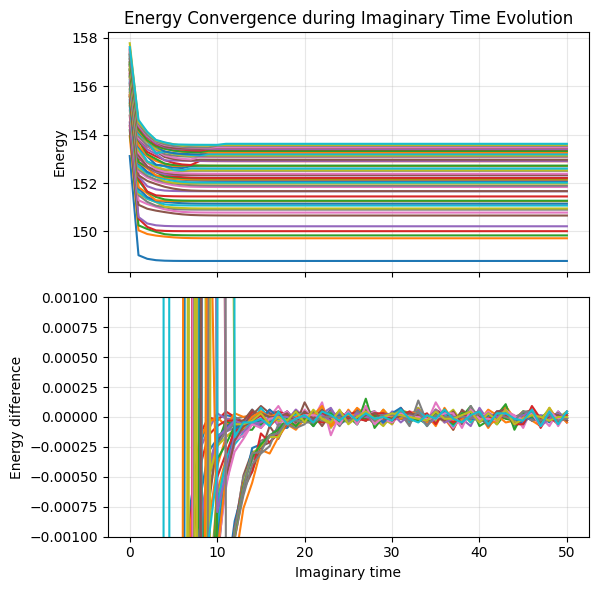

In [84]:
# Plot energy convergence
fig, ax = plt.subplots(2,1, figsize=(6, 6), sharex=True)
ax[0].plot(ts, np.real(energies))
#ax[0].set_xlabel('Imaginary time')
ax[0].set_ylabel('Energy')
ax[0].set_title('Energy Convergence during Imaginary Time Evolution')
ax[0].grid(True, alpha=0.3)

ax[1].plot(ts[1:], np.diff(np.real(energies), axis=0))
ax[1].set_xlabel('Imaginary time')
ax[1].set_ylabel('Energy difference')
ax[1].grid(True, alpha=0.3)

plt.ylim(-1e-3, 1e-3)

plt.tight_layout()
plt.show()

In [85]:
y_final = mctdhf.rotate_to_natural_orbitals(y_final)
C_final, bs_final = mctdhf._y_to_Cb(y_final)
F = qubit_corner_fidelities(C_final, 4, 2)
matched_idx, fidelities, loss = match_configs(F)

In [92]:
sl = (slice(None),) + (slice(0, 2),) * 4
print(sl)
print(C_final[sl])

(slice(None, None, None), slice(0, 2, None), slice(0, 2, None), slice(0, 2, None), slice(0, 2, None))
[[[[[-9.99240041e-01+0.j  2.04170239e-03+0.j]
    [ 7.06732133e-03+0.j -1.69013590e-02+0.j]]

   [[-1.85306033e-03+0.j  3.22765368e-03+0.j]
    [ 2.30457764e-02+0.j -1.06163330e-04+0.j]]]


  [[[-4.63660079e-04+0.j -9.78067750e-04+0.j]
    [-3.93436244e-03+0.j  6.44166812e-06+0.j]]

   [[ 2.47146003e-02+0.j -4.34908288e-05+0.j]
    [-1.22876561e-04+0.j  4.53815563e-04+0.j]]]]



 [[[[ 1.12119515e-03+0.j  2.00506337e-02+0.j]
    [ 1.08246848e-01+0.j -2.99472333e-04+0.j]]

   [[-4.60604429e-01+0.j  7.25139806e-04+0.j]
    [ 1.56226743e-03+0.j -8.59205797e-03+0.j]]]


  [[[ 8.79294336e-01+0.j -1.45515136e-03+0.j]
    [-4.68534743e-03+0.j  1.50498860e-02+0.j]]

   [[-7.79567845e-03+0.j -3.77248041e-03+0.j]
    [-2.47171521e-02+0.j -6.70300142e-05+0.j]]]]



 [[[[ 3.87070025e-03+0.j  4.34549935e-02+0.j]
    [ 2.49121770e-01+0.j -6.11002732e-04+0.j]]

   [[-8.42381716e-01+0.j  1.32094102e-03

In [87]:
F

Array([[9.98480678e-01, 4.16854846e-06, 4.99470298e-05, 2.85655929e-04,
        3.43383249e-06, 1.04177479e-05, 5.31107828e-04, 1.12706529e-08,
        2.14980673e-07, 9.56616532e-07, 1.54792069e-05, 4.14950886e-11,
        6.10811461e-04, 1.89145211e-09, 1.50986494e-08, 2.05948567e-07],
       [1.25707857e-06, 4.02027916e-04, 1.17173800e-02, 8.96836809e-08,
        2.12156445e-01, 5.25827716e-07, 2.44067951e-06, 7.38234594e-05,
        7.73158550e-01, 2.11746556e-06, 2.19524809e-05, 2.26499062e-04,
        6.07726033e-05, 1.42316085e-05, 6.10937597e-04, 4.49302284e-09],
       [1.49823209e-05, 1.88833650e-03, 6.20616563e-02, 3.73324326e-07,
        7.09606946e-01, 1.74488514e-06, 7.77375044e-06, 2.57100386e-04,
        2.24046052e-01, 6.43799069e-07, 6.53587313e-06, 5.75588419e-05,
        3.11295044e-05, 1.42693438e-07, 2.09619520e-06, 7.29362171e-09],
       [4.50310181e-05, 4.30266745e-02, 8.78597498e-01, 7.38511653e-06,
        7.55059198e-02, 5.67216709e-08, 3.30217008e-05, 9.912

In [86]:
matched_idx

array([ 0,  4,  3, 13,  2, 12,  9, 27,  1, 10,  8, 26,  5, 20, 19, 45])

In [ ]:
# ── Step 2 code: sanity check at the physical starting point ──────────────────

alphas_start = [7., 8., 9., 10.]    # GHz — single-excitation detunings ~1 GHz
betas_start  = [0.15] * num_wells   # GHz — anharmonicity comparable to inter-well J at ~1 µm

res0 = evaluate_params(alphas_start, betas_start, num_steps=2000)

print(f"loss = {res0['loss']:.4f}    min fidelity = {res0['fidelities'].min():.4f}")
print(f"lowest 16 eigenvalues: {np.round(res0['energies'][:16], 4)}")
print()
for cfg, f, idx in zip(CONFIGS, res0['fidelities'], res0['matched_idx']):
    print(f"  {cfg} -> eigenstate {idx:2d}, F = {f:.4f}, E = {res0['energies'][idx]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={'width_ratios': [1, 2]})
plot_qubit_ladder(res0['energies'], res0['matched_idx'], CONFIGS,
                  ax=axes[0], title='Energy ladder')
plot_fidelity_bars(res0['fidelities'], CONFIGS,
                   ax=axes[1], title='Matched fidelities at start')
plt.tight_layout()
plt.show()

## Step 3 — Nelder–Mead with warm-starting

scipy Nelder–Mead on the 8-vector `[α₀..α₃, β₀..β₃]` (GHz). Bounds `α ∈ [5, 15]`, `β ∈ [0.02, 0.4]` are enforced via a quadratic penalty (no inner ITE on out-of-bounds proposals — the penalty alone steers the simplex back).

**Warm-start.** Between adjacent evaluations the change in (α, β) is small, so the previous converged 50-state manifold is a much better initial guess than the default single-particle product state. The first call runs cold (`num_steps=2000`, plus `noise_C=1e-3`); subsequent calls reuse `y_final` from the prior eval and run with `num_steps=500`.

Wall time: ~1–2 hours total. Each cold ITE takes ~tens of seconds; each warm one is ~4× faster.

In [ ]:
# ── Step 3 code: Nelder-Mead with warm-starting ───────────────────────────────

from scipy.optimize import minimize
import time

ALPHA_BOUNDS = (5.0, 15.0)
BETA_BOUNDS  = (0.02, 0.4)
PENALTY      = 1e3   # quadratic penalty coefficient outside bounds


def out_of_bounds_penalty(x):
    """Quadratic penalty so Nelder-Mead steers back inside the box."""
    pen = 0.0
    for a in x[:num_wells]:
        pen += PENALTY * max(0., ALPHA_BOUNDS[0] - a)**2
        pen += PENALTY * max(0., a - ALPHA_BOUNDS[1])**2
    for b in x[num_wells:]:
        pen += PENALTY * max(0., BETA_BOUNDS[0] - b)**2
        pen += PENALTY * max(0., b - BETA_BOUNDS[1])**2
    return pen


x0 = np.array([7., 8., 9., 10., 0.15, 0.15, 0.15, 0.15])

# Closure state: rolling y_prev (warm-start), best-so-far, full trajectory.
opt_state = dict(y_prev=None, best_loss=np.inf, best_x=None, best_result=None,
                 traj=[], i=0)


def loss_fn(x):
    """scipy callback: penalty if OOB, else evaluate_params with warm-start."""
    opt_state["i"] += 1
    pen = out_of_bounds_penalty(x)
    if pen > 0:
        opt_state["traj"].append(dict(x=x.copy(), loss=pen, oob=True))
        print(f"[{opt_state['i']:03d}] OOB  penalty={pen:.2f}")
        return pen

    n_steps = 2000 if opt_state["y_prev"] is None else 500
    t0 = time.time()
    r = evaluate_params(x[:num_wells], x[num_wells:],
                        y_prev=opt_state["y_prev"], num_steps=n_steps)
    wall = time.time() - t0

    print(f"[{opt_state['i']:03d}] α={np.round(x[:4], 3)}  β={np.round(x[4:], 3)}  "
          f"loss={r['loss']:.4f}  min_fid={r['fidelities'].min():.3f}  {wall:.1f}s")

    opt_state["y_prev"] = r["y_final"]                  # warm-start next call
    if r["loss"] < opt_state["best_loss"]:
        opt_state["best_loss"] = r["loss"]
        opt_state["best_x"]    = x.copy()
        opt_state["best_result"] = r
    opt_state["traj"].append(dict(x=x.copy(), loss=r["loss"],
                                   min_fid=float(r["fidelities"].min()), oob=False))
    return r["loss"]


res = minimize(loss_fn, x0, method='Nelder-Mead',
               options=dict(xatol=1e-3, fatol=5e-3, maxiter=200, disp=True))

alpha_star = opt_state["best_x"][:num_wells]
beta_star  = opt_state["best_x"][num_wells:]
print(f"\nBest α (GHz) = {alpha_star}")
print(f"Best β (GHz) = {beta_star}")
print(f"Best loss    = {opt_state['best_loss']:.4f}")

# Plot loss + worst-fidelity trajectories.
losses_all = [t["loss"] for t in opt_state["traj"]]
min_fids   = [t["min_fid"] for t in opt_state["traj"] if not t["oob"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(losses_all, 'o-', ms=3); axes[0].set_yscale('log')
axes[0].set_xlabel('evaluation'); axes[0].set_ylabel('loss')
axes[0].grid(True, alpha=0.3); axes[0].set_title('Loss vs evaluation')
axes[1].plot(min_fids, 'o-', ms=3)
axes[1].set_xlabel('in-bounds eval'); axes[1].set_ylabel('min fidelity')
axes[1].grid(True, alpha=0.3); axes[1].set_title('Worst-config fidelity vs evaluation')
plt.tight_layout()
plt.show()

## Step 4 — Inspect the best parameters

Run a fresh cold ITE at (α*, β*) (the warm-start state from the optimiser is correlated with all the intermediate evaluations and not a clean baseline). Print per-config matched eigenstates and plot.

In [ ]:
# ── Step 4 code: re-evaluate at the optimum and plot ──────────────────────────

res_best = evaluate_params(alpha_star, beta_star, num_steps=2000)

print(f"loss = {res_best['loss']:.4f}    min fidelity = {res_best['fidelities'].min():.4f}")
worst = int(np.argmin(res_best['fidelities']))
print(f"worst config: {CONFIGS[worst]}, F = {res_best['fidelities'][worst]:.4f}")
print()
for cfg, f, idx in zip(CONFIGS, res_best['fidelities'], res_best['matched_idx']):
    print(f"  {cfg} -> eigenstate {idx:2d}, F = {f:.4f}, E = {res_best['energies'][idx]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={'width_ratios': [1, 2]})
plot_qubit_ladder(res_best['energies'], res_best['matched_idx'], CONFIGS,
                  ax=axes[0], title='Energy ladder at (α*, β*)')
plot_fidelity_bars(res_best['fidelities'], CONFIGS,
                   ax=axes[1], title='Matched fidelities at (α*, β*)')
plt.tight_layout()
plt.show()